# ENTREGA 2 · Predicción del precio de la vivienda
Idealista18 (Madrid, Barcelona y Valencia, 2018). Notebook de análisis exploratorio, preprocesado y primeros modelos.

**Autores:** Javier Alacio Vega y Javier Gaudencio Ortega Lucena · Aprendizaje Automático · UFV Madrid

**Índice**
1. Configuración y carga de datos
2. Análisis exploratorio (EDA)
3. Preprocesado e ingeniería de características
4. Modelos: regresión lineal (referencia) y perceptrón multicapa
5. Resultados y próximos pasos

**Datos:** Idealista18 (licencia ODbL-1.0), anuncios de venta de 2018. Para generar el CSV a partir de los archivos `.rda`: `python src/convertir_datos.py`.

> **Nota sobre esta versión (revisada después de la fecha de entrega, 13/11/2026).**
> La versión entregada se conserva en la etiqueta de git `entrega2` (se puede recuperar con `git checkout entrega2`).
> Los cambios respecto a esa versión son:
> 1. El código de la red se ha reescrito para que sea más legible y reutilizable: una clase `RedPrecios` y una función `entrenar_red`. La arquitectura (21 → 64 → 32 → 1), el optimizador (Adam), la tasa de aprendizaje y el tamaño de lote **no cambian**.
> 2. El tope de épocas pasa de 19 a 100, de modo que la parada temprana (paciencia 8) es la que decide cuándo parar.
> 3. La semilla, la creación de la red y el entrenamiento están en la misma celda, para que cada ejecución empiece desde cero.
>
> Por el punto 2, los resultados del perceptrón multicapa difieren ligeramente de los del documento entregado, que corresponden a la versión anterior. La regresión lineal no cambia.

## 1. Configuración y carga de datos

### LIBRERIAS

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 60)

### CARGAR DATOS

In [32]:
RUTA = Path("../data/idealista18_venta_3ciudades.csv")
df = pd.read_csv(RUTA)
print(df.shape)
df.head()

(189923, 44)


,ASSETID,PERIOD,PRICE,UNITPRICE,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,HASTERRACE,HASLIFT,HASAIRCONDITIONING,AMENITYID,HASPARKINGSPACE,ISPARKINGSPACEINCLUDEDINPRICE,PARKINGSPACEPRICE,HASNORTHORIENTATION,HASSOUTHORIENTATION,HASEASTORIENTATION,HASWESTORIENTATION,HASBOXROOM,HASWARDROBE,HASSWIMMINGPOOL,HASDOORMAN,HASGARDEN,ISDUPLEX,ISSTUDIO,ISINTOPFLOOR,CONSTRUCTIONYEAR,FLOORCLEAN,FLATLOCATIONID,CADCONSTRUCTIONYEAR,CADMAXBUILDINGFLOOR,CADDWELLINGCOUNT,CADASTRALQUALITYID,BUILTTYPEID_1,BUILTTYPEID_2,BUILTTYPEID_3,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,DISTANCE_TO_CASTELLANA,LONGITUDE,LATITUDE,CITY,DISTANCE_TO_DIAGONAL,DISTANCE_TO_BLASCO
0,A15019136831406238029,201803,126000.0,2680.851064,47,1,1,0,1,1,3,0,0,1.0,0,0,0,0,1,1,1,1,1,0,0,0,2005.0,1.0,1.0,2005,7,319,3.0,0,1,0,8.058429,0.872075,6.868677,-3.766933,40.362485,Madrid,NaN,NaN
1,A6677225905472065344,201803,235000.0,4351.851852,54,1,1,0,0,0,3,0,0,1.0,0,0,0,0,0,1,0,0,0,0,0,0,NaN,1.0,2.0,1900,5,11,3.0,0,0,1,0.876369,0.116382,1.544125,-3.710725,40.422430,Madrid,NaN,NaN
2,A13341979748618524775,201803,373000.0,4973.333333,75,2,1,0,0,1,3,0,0,1.0,0,1,0,0,1,1,0,0,0,0,0,0,NaN,3.0,1.0,1915,6,26,3.0,0,0,1,0.907479,0.139109,1.608444,-3.711571,40.422190,Madrid,NaN,NaN
3,A4775182175615276542,201803,284000.0,5916.666667,48,1,1,0,1,1,3,0,0,1.0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,1.0,2.0,1947,9,15,5.0,0,0,1,0.845462,0.144299,1.516166,-3.710440,40.422251,Madrid,NaN,NaN
4,A2492087730711701973,201803,228000.0,4560.000000,50,0,1,0,0,0,3,0,0,1.0,0,0,0,0,0,0,0,0,0,0,1,0,1930.0,0.0,1.0,1930,5,19,7.0,0,0,1,1.250231,0.337098,1.794136,-3.714340,40.408741,Madrid,NaN,NaN


## 2. Análisis exploratorio (EDA)
Qué datos tenemos, qué problemas tienen y qué decisiones de limpieza tomamos.

### Cuántos anuncios hay por ciudad y que trimestres cubre
PERIOD es el trimestre en formato año + mes: 201803 es marzo de 2018

In [33]:
print(df.CITY.value_counts()) #value_counts() cuenta cuantas filas hay de cada valor
print(sorted(df.PERIOD.unique())) #ordenamos los periodos y sacamos solo los valores distintos

CITY
Madrid       94815
Barcelona    61486
Valencia     33622
Name: count, dtype: int64
[np.int64(201803), np.int64(201806), np.int64(201809), np.int64(201812)]


### Comprobar si hay inmuebles repetidos
ASSETID es el identificador del inmueble

In [34]:
apariciones = df.groupby("ASSETID").size() #agrupamos las filas por identificador de inmueble y cuenta cuantas tiene cada uno
print("Filas:", len(df))
print("Inmuebles distintos:", apariciones.size)
apariciones.value_counts().sort_index()

Filas: 189923
Inmuebles distintos: 149923


1     121349
2      20018
3       6484
4       1500
5        414
6        115
7         28
8          9
9          3
10         2
11         1
Name: count, dtype: int64

### Columnas con valores vacíos (NaN)

In [35]:
faltan = (df.isna().mean() * 100).round(2).sort_values(ascending=False) #marcamos la celda vacia y la pasamos a porcentaje
faltan[faltan > 0]

DISTANCE_TO_BLASCO        82.30
DISTANCE_TO_DIAGONAL      67.63
DISTANCE_TO_CASTELLANA    50.08
CONSTRUCTIONYEAR          48.47
FLATLOCATIONID            10.30
FLOORCLEAN                 5.18
dtype: float64

### Comparacion de las dos columnas de año de construcción para saber cuál usar

In [36]:
print("Faltantes CONSTRUCTIONYEAR:", round(df.CONSTRUCTIONYEAR.isna().mean() * 100, 1), "%")
print("Faltantes CADCONSTRUCTIONYEAR:", round(df.CADCONSTRUCTIONYEAR.isna().mean() * 100, 1), "%")
print("Valores iguales a 1900 en CONSTRUCTIONYEAR:", (df.CONSTRUCTIONYEAR == 1900).sum())
print(df[["CONSTRUCTIONYEAR", "CADCONSTRUCTIONYEAR"]].corr())

Faltantes CONSTRUCTIONYEAR: 48.5 %
Faltantes CADCONSTRUCTIONYEAR: 0.0 %
Valores iguales a 1900 en CONSTRUCTIONYEAR: 4946
                     CONSTRUCTIONYEAR  CADCONSTRUCTIONYEAR
CONSTRUCTIONYEAR             1.000000             0.611745
CADCONSTRUCTIONYEAR          0.611745             1.000000


### Estadísticas de los precios


In [37]:
print(df["PRICE"].describe().round(0)) #describe() da el resumen de la media, minimo, maximo y los percentiles (25%, 50% (mediana) y el 75 %)
print("Asimetría del precio:", round(df["PRICE"].skew(), 2)) #skew() mide la simetría

count     189923.0
mean      361226.0
std       351674.0
min        20000.0
25%       160000.0
50%       261000.0
75%       428000.0
max      8133000.0
Name: PRICE, dtype: float64
Asimetría del precio: 4.18


### Dibujamos el precio y su logaritmo

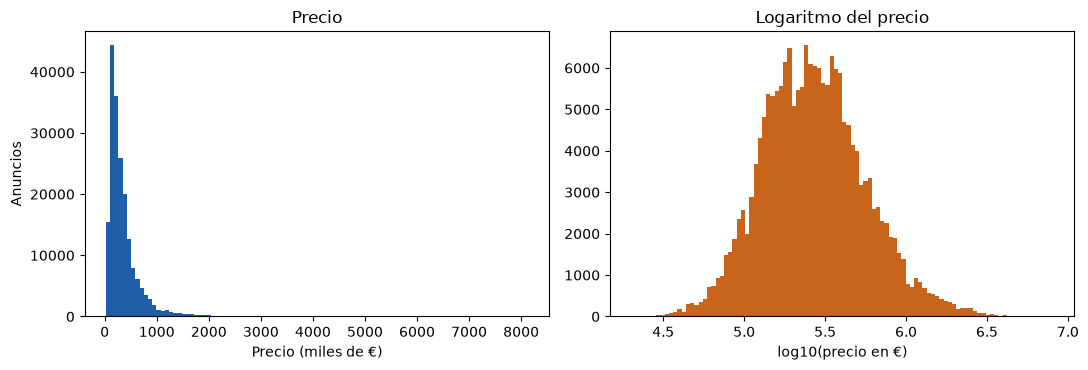

Asimetría del log(precio): 0.3


In [38]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df["PRICE"] / 1e3, bins=100, color="#1F5FA8")
ax[0].set_xlabel("Precio (miles de €)")
ax[0].set_ylabel("Anuncios")
ax[0].set_title("Precio")
ax[1].hist(np.log10(df["PRICE"]), bins=100, color="#C8651B")
ax[1].set_xlabel("log10(precio en €)")
ax[1].set_title("Logaritmo del precio")
fig.tight_layout()
plt.show()
print("Asimetría del log(precio):", round(np.log(df["PRICE"]).skew(), 2))

Gráfica de la izquierda (precio): casi todos los anuncios se amontonan entre 0 y 1.000 mil euros, y hay una cola larguísima hasta 8,1 millones. La asimetría de 4,18 lo confirma. También se ve en los números: la media (361.226 €) es bastante mayor que la mediana (261.000 €), porque unas pocas viviendas muy caras la arrastran hacia arriba.

Gráfica de la derecha (logaritmo): la forma pasa a ser casi una campana simétrica, y la asimetría baja a 0,30. El logaritmo convierte “multiplicar el precio” en “sumar”, así que un salto de 100.000 a 200.000 € pesa lo mismo que uno de 500.000 a 1.000.000 €.

Por qué importa para entrenar la red. El modelo aprende minimizando el error cuadrático. Con precios en euros, un fallo de 500.000 € en un ático de 8 millones pesaría 25 veces más que uno de 100.000 € en un piso de 150.000 €, y la red dedicaría casi todo su esfuerzo a las viviendas de lujo, que son muy pocas. Con el logaritmo, los errores son relativos (en porcentaje) y todas las viviendas cuentan de forma más equilibrada. Después deshacemos el logaritmo para dar los resultados en euros (MAE y RMSE), que es lo que se entiende.

### Precio mediano por ciudad

In [39]:
orden = ["Madrid", "Barcelona", "Valencia"]
#Separamos las filas por ciuidad y calculamos la mediana de cada columna dentro de cada una
#UNITPRICE es el precio por metro cuadrado
df.groupby("CITY")[["PRICE", "UNITPRICE", "CONSTRUCTEDAREA"]].median().loc[orden].round(0) 

,PRICE,UNITPRICE,CONSTRUCTEDAREA
CITY,,,
Madrid,262000.0,3480.0,83.0
Barcelona,325000.0,3991.0,82.0
Valencia,151000.0,1531.0,100.0


### Comparar la distribución del precio entre ciudades.

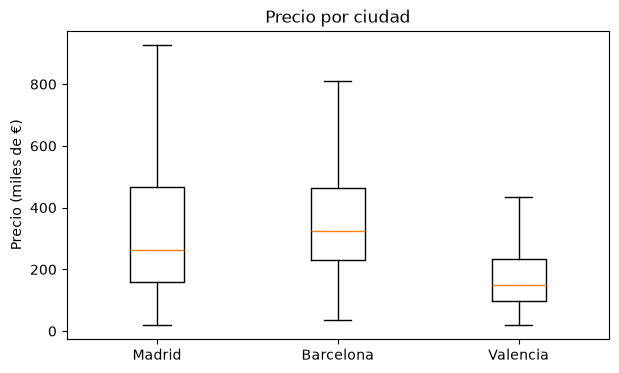

In [40]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df["CITY"] == c, "PRICE"] / 1e3 for c in orden], #box plot para ver los outliers
           tick_labels=orden, showfliers=False)
ax.set_ylabel("Precio (miles de €)")
ax.set_title("Precio por ciudad")
plt.show()

### Contar cuántos anuncios tienen valores raros según unas reglas razonables.

In [41]:
#Los umbrales son decisiones propias, no seguimos ninguna regla oficial, ponemos los valores que consideramos atipicos

reglas = {
    "Más de 8 habitaciones": df["ROOMNUMBER"] > 8,
    "Más de 8 baños": df["BATHNUMBER"] > 8,
    "0 habitaciones (posibles estudios)": df["ROOMNUMBER"] == 0,
    "Superficie > 500 m²": df["CONSTRUCTEDAREA"] > 500,
    "Superficie < 25 m²": df["CONSTRUCTEDAREA"] < 25,
    "Distancia al centro > 30 km": df["DISTANCE_TO_CITY_CENTER"] > 30,
    "Distancia al metro > 30 km": df["DISTANCE_TO_METRO"] > 30,
    "Precio > 3 millones": df["PRICE"] > 3_000_000,
}
tabla = pd.DataFrame({"casos": {k: int(v.sum()) for k, v in reglas.items()}})
tabla["porcentaje"] = (tabla["casos"] / len(df) * 100).round(3)
tabla

,casos,porcentaje
Más de 8 habitaciones,184,0.097
Más de 8 baños,52,0.027
0 habitaciones (posibles estudios),4146,2.183
Superficie > 500 m²,324,0.171
Superficie < 25 m²,316,0.166
Distancia al centro > 30 km,1,0.001
Distancia al metro > 30 km,1,0.001
Precio > 3 millones,288,0.152


### Resumen estadístico de las variables principales, para ver los extremos.

In [42]:
cols = ["PRICE", "CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER",
        "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]
df[cols].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1)

,count,mean,std,min,1%,50%,99%,max
PRICE,189923.0,361225.9,351673.7,20000.0,56000.0,261000.0,1834000.0,8133000.0
CONSTRUCTEDAREA,189923.0,100.8,59.7,21.0,30.0,86.0,332.0,985.0
ROOMNUMBER,189923.0,2.8,1.2,0.0,0.0,3.0,6.0,93.0
BATHNUMBER,189923.0,1.6,0.8,0.0,1.0,1.0,4.0,20.0
DISTANCE_TO_CITY_CENTER,189923.0,3.5,2.5,0.0,0.3,3.0,11.0,415.8
DISTANCE_TO_METRO,189923.0,0.4,1.0,0.0,0.0,0.3,2.0,399.5


- Habitaciones y baños: el 99 % de las viviendas tiene como mucho 6 habitaciones y 4 baños, pero el máximo es de 93 habitaciones y 20 baños. Esos extremos son casi seguro errores de captura.

- Distancias: el 99 % está a menos de 11 km del centro y a 2 km del metro. El máximo, 415,8 km del centro, es imposible dentro de una ciudad (será una coordenada errónea).

- Superficie: 985 m² es un máximo muy grande, pero encaja con un chalet, y el 0,17 % de casos por encima de 500 m² es normal en un mercado con casas de lujo. No tengo motivos para tratarlo como error.

- Precio: el máximo es de 8,1 millones y el 99 % está por debajo de 1,8 millones. Son viviendas caras, pero reales. No las eliminamos, y el logaritmo ya reduce su peso.

- Eliminar los errores evidentes: más de 8 habitaciones, más de 8 baños, y distancias de más de 30 km (en total, unas 235 filas, el 0,12 % de los datos).

- Conservar las superficies grandes y pequeñas, los precios altos y las viviendas con 0 habitaciones.

### ¿Las viviendas con 0 habitaciones son estudios? 

Utilizamos la columna ISSTUDIO para comprobarlo

In [43]:
print(df.loc[df["ROOMNUMBER"] == 0, "ISSTUDIO"].value_counts(normalize=True).round(3))

ISSTUDIO
1    0.93
0    0.07
Name: proportion, dtype: float64


### Eliminar los errores evidentes y guardar el resultado en un nuevo df_limpio

In [44]:
sospechoso = ((df["ROOMNUMBER"] > 8) | (df["BATHNUMBER"] > 8) |
              (df["DISTANCE_TO_CITY_CENTER"] > 30) | (df["DISTANCE_TO_METRO"] > 30))
print("Filas a eliminar:", sospechoso.sum())
df_limpio = df[~sospechoso].copy() #creamos un copia limpia
print("Filas que quedan:", len(df_limpio))

Filas a eliminar: 192
Filas que quedan: 189731


### Qué variables están más ligadas al precio

- corr(method="spearman") mide hasta qué punto, al subir una variable, sube o baja el precio. Va de -1 (sube una y baja la otra) a +1 (suben las dos juntas), y 0 es que no hay relación.

- Usamos Spearman en lugar de la correlación habitual porque no exige que la relación sea una línea recta, solo que vayan en el mismo sentido, y es menos sensible a los valores extremos.

- Obviamente quitamos la correlación del precio consigo mismo (que sería 1), mediante .drop("logPRICE")

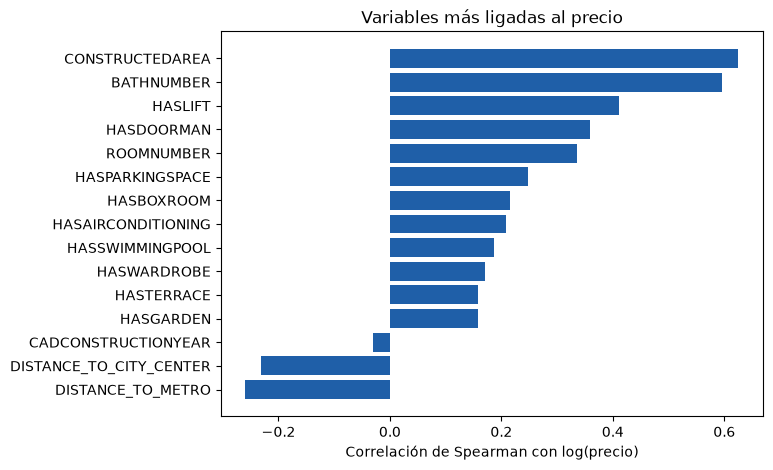

In [45]:
num = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "CADCONSTRUCTIONYEAR",
       "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO", "HASTERRACE", "HASLIFT",
       "HASAIRCONDITIONING", "HASPARKINGSPACE", "HASSWIMMINGPOOL", "HASGARDEN",
       "HASDOORMAN", "HASWARDROBE", "HASBOXROOM"]
d = df_limpio[num].copy()
d["logPRICE"] = np.log(df_limpio["PRICE"])
corr = d.corr(method="spearman")["logPRICE"].drop("logPRICE").sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(corr.index, corr.values, color="#1F5FA8")
ax.set_xlabel("Correlación de Spearman con log(precio)")
ax.set_title("Variables más ligadas al precio")
plt.show()

- Lo más ligado al precio: la superficie (≈0,62) y los baños (≈0,60). Después vienen el ascensor (≈0,41), el portero (≈0,36) y las habitaciones (≈0,34). Es curioso que los baños pesen más que las habitaciones: suelen indicar viviendas más grandes y de mayor categoría. Además superficie y baños van muy juntas, así que cuentan en parte la misma información.

- Negativas: la distancia al metro y al centro (≈-0,25): cuanto más lejos, más barata.
- Casi nada: el año de construcción catastral (≈-0,03). No significa que no importe, sino que no hay una relación simple “más nuevo = más caro” (hay edificios antiguos muy caros en el centro y nuevos baratos en las afueras).

- Precaución: una correlación no demuestra que una cosa cause la otra. Un edificio con portero y ascensor suele estar en una zona cara, y esa zona es la que sube el precio.

### Precio frente a superficie, por ciudad

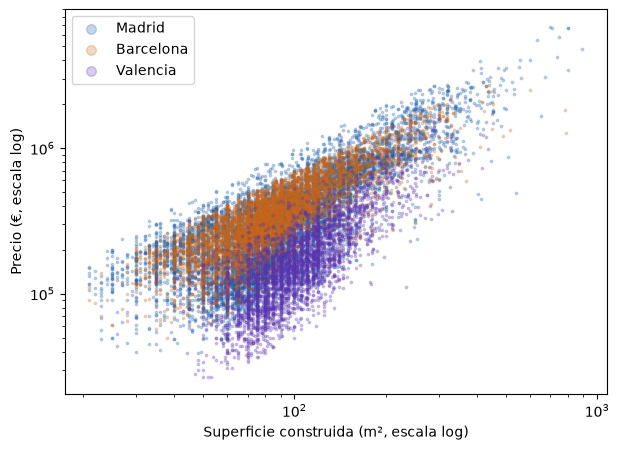

In [46]:
muestra = df_limpio.sample(20000, random_state=42)
colores = {"Madrid": "#1F5FA8", "Barcelona": "#C8651B", "Valencia": "#5B34B0"}

fig, ax = plt.subplots(figsize=(7, 5))
for c in orden:
    s = muestra[muestra["CITY"] == c]
    ax.scatter(s["CONSTRUCTEDAREA"], s["PRICE"], s=3, alpha=0.25, label=c, color=colores[c])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Superficie construida (m², escala log)")
ax.set_ylabel("Precio (€, escala log)")
ax.legend(markerscale=4)
plt.show()

- La tendencia es una diagonal clara: en escala logarítmica, a más superficie, proporcionalmente más precio.

- Valencia (morado) queda claramente por debajo de las otras dos: para la misma superficie, cuesta bastante menos. Madrid y Barcelona se solapan, y Madrid es la más dispersa.

- Esto confirma que la ciudad tiene que ser una entrada del modelo, además de la superficie.

## 3. Preprocesado e ingeniería de características
Elección de variables, separación entrenamiento/validación/prueba **por inmueble**, nuevas variables y estandarización.

### Elegimos las variables de entradas

- Dividimos las variables en dos lista VARIABLES NUMÉRICAS y VARIABLES BINARIAS

- Obviamente hemos dejado fuera PRICE, UNITPRICE (se calcula con el precio, sería hacer trampa), ASSETID, las distancias propias de cada ciudad, CONSTRUCTIONYEAR y las variables de

In [47]:
VARIABLES_NUM = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "CADCONSTRUCTIONYEAR",
                 "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]
VARIABLES_BIN = ["HASTERRACE", "HASLIFT", "HASAIRCONDITIONING", "HASPARKINGSPACE",
                 "HASSWIMMINGPOOL", "HASGARDEN", "HASDOORMAN", "HASWARDROBE", "HASBOXROOM",
                 "ISSTUDIO", "ISDUPLEX", "ISINTOPFLOOR"]
print(len(VARIABLES_NUM), "numéricas y", len(VARIABLES_BIN), "de sí/no")

6 numéricas y 12 de sí/no


### Montar la tabla de entradas X y el objetivo y

In [48]:
X = df_limpio[VARIABLES_NUM + VARIABLES_BIN].copy()
X = X.join(pd.get_dummies(df_limpio["CITY"], prefix="CITY", dtype=int))
y = np.log(df_limpio["PRICE"])
grupos = df_limpio["ASSETID"]

print("X:", X.shape, "| y:", y.shape)
print("Valores vacíos en X:", X.isna().sum().sum())
X.head(3)

X: (189731, 21) | y: (189731,)
Valores vacíos en X: 0


,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,CADCONSTRUCTIONYEAR,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,HASTERRACE,HASLIFT,HASAIRCONDITIONING,HASPARKINGSPACE,HASSWIMMINGPOOL,HASGARDEN,HASDOORMAN,HASWARDROBE,HASBOXROOM,ISSTUDIO,ISDUPLEX,ISINTOPFLOOR,CITY_Barcelona,CITY_Madrid,CITY_Valencia
0,47,1,1,2005,8.058429,0.872075,0,1,1,0,1,1,1,1,1,0,0,0,0,1,0
1,54,1,1,1900,0.876369,0.116382,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0
2,75,2,1,1915,0.907479,0.139109,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0


- X son las entradas del modelo, y y lo que queremos predecir: el logaritmo del precio.

- pd.get_dummies convierte la ciudad (texto) en tres columnas de 0/1: Madrid pasa a ser [1, 0, 0]. Un modelo solo entiende números, y esto evita inventar un orden entre ciudades (que Valencia “valga” más que Madrid, por ejemplo).

- grupos guarda el identificador del inmueble: lo usaremos para separar entrenamiento y prueba sin repetir pisos.

### Dividir en entrenamiento (70 %), validación (15 %) y prueba (15 %).

- GroupShuffleSplit mezcla al azar, pero respetando los grupos: todas las filas con el mismo ASSETID caen siempre en el mismo conjunto.

- random_state=42 fija el azar para que el reparto sea siempre el mismo, que es importante para reproducir resultados.

- Cada conjunto tiene su función:
    - entrenamiento: el modelo aprende con él;
    - validación: sirve para elegir y ajustar el modelo (más adelante, parada temprana y algoritmo genético);
    - prueba: se usa una sola vez al final, para medir cómo funciona con viviendas nunca vistas.

In [49]:
from sklearn.model_selection import GroupShuffleSplit

# 1) 70 % para entrenamiento, 30 % para el resto
gss = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
idx_train, idx_resto = next(gss.split(X, y, groups=grupos))

X_resto, y_resto, g_resto = X.iloc[idx_resto], y.iloc[idx_resto], grupos.iloc[idx_resto]

# 2) el 30 % restante se reparte a partes iguales: validación y prueba
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
idx_val, idx_test = next(gss2.split(X_resto, y_resto, groups=g_resto))

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_val,   y_val   = X_resto.iloc[idx_val],  y_resto.iloc[idx_val]
X_test,  y_test  = X_resto.iloc[idx_test], y_resto.iloc[idx_test]

### Comprobar que el reparto es correcto

In [50]:
ids_train = set(grupos.iloc[idx_train])
ids_val = set(g_resto.iloc[idx_val])
ids_test = set(g_resto.iloc[idx_test])

print("Filas -> entrenamiento:", len(X_train), "| validación:", len(X_val), "| prueba:", len(X_test))
print("Inmuebles compartidos entrenamiento/validación:", len(ids_train & ids_val))
print("Inmuebles compartidos entrenamiento/prueba:", len(ids_train & ids_test))
print("Inmuebles compartidos validación/prueba:", len(ids_val & ids_test))

Filas -> entrenamiento: 132753 | validación: 28485 | prueba: 28493
Inmuebles compartidos entrenamiento/validación: 0
Inmuebles compartidos entrenamiento/prueba: 0
Inmuebles compartidos validación/prueba: 0


### Creamos la variable ANTIGUEDAD, la edad del edificio en 2018

- Es más fácil de interpretar para el modelo que el año suelto.

- clip(upper=200) limita la antigüedad a 200 años. Hay unos 128 edificios con años anteriores a 1800 que serían valores extremos, y así no distorsionan.

- Quitamos CADCONSTRUCTIONYEAR porque dice lo mismo que ANTIGUEDAD (una es la otra reflejada) y las dos juntas no aportarían nada.


In [51]:
def crear_caracteristicas(d):
    d = d.copy()
    d["ANTIGUEDAD"] = (2018 - d["CADCONSTRUCTIONYEAR"]).clip(upper=200)
    d["CONSTRUCTEDAREA"] = np.log(d["CONSTRUCTEDAREA"])   # NUEVO: logaritmo de la superficie
    return d.drop(columns="CADCONSTRUCTIONYEAR")

X_train = crear_caracteristicas(X_train)
X_val = crear_caracteristicas(X_val)
X_test = crear_caracteristicas(X_test)
print(X_train["ANTIGUEDAD"].describe().round(1))

count    132753.0
mean         55.7
std          31.5
min           0.0
25%          39.0
50%          52.0
75%          67.0
max         200.0
Name: ANTIGUEDAD, dtype: float64


### Estandarizamos las variables numéricas

- Estandarizar es restar la media y dividir por la desviación. La superficie va de 21 a 985 y los baños de 0 a 8: sin estandarizar, la red daría más peso a lo que tiene números grandes. Después, todas las variables tienen media 0 y desviación 1.

- El escalador se ajusta (fit) solo con el conjunto de entrenamiento y luego se aplica a los tres. Si lo calculáramos con todos los datos, la prueba influiría en el entrenamiento sin que nos diéramos cuenta.

- Las variables binarias (0 o 1) no se estandarizan.

In [52]:
from sklearn.preprocessing import StandardScaler

NUM = ["CONSTRUCTEDAREA", "ROOMNUMBER", "BATHNUMBER", "ANTIGUEDAD",
       "DISTANCE_TO_CITY_CENTER", "DISTANCE_TO_METRO"]

escalador = StandardScaler().fit(X_train[NUM])

def escalar(d):
    d = d.copy()
    d[NUM] = escalador.transform(d[NUM])
    return d

Xs_train, Xs_val, Xs_test = escalar(X_train), escalar(X_val), escalar(X_test)
print("Medias:", Xs_train[NUM].mean().round(2).to_dict())
print("Desviaciones:", Xs_train[NUM].std().round(2).to_dict())

Medias: {'CONSTRUCTEDAREA': 0.0, 'ROOMNUMBER': -0.0, 'BATHNUMBER': 0.0, 'ANTIGUEDAD': 0.0, 'DISTANCE_TO_CITY_CENTER': -0.0, 'DISTANCE_TO_METRO': 0.0}
Desviaciones: {'CONSTRUCTEDAREA': 1.0, 'ROOMNUMBER': 1.0, 'BATHNUMBER': 1.0, 'ANTIGUEDAD': 1.0, 'DISTANCE_TO_CITY_CENTER': 1.0, 'DISTANCE_TO_METRO': 1.0}


## 4. Modelos
Primero una regresión lineal como referencia y después el perceptrón multicapa (MLP), el modelo principal.

### Primer modelo, la regresión lineal de referencia

La regresión lineal busca la combinación de las variables que mejor reproduce el log-precio. Es nuestro “listón”: cualquier modelo más complejo debe mejorarla.

La función evaluar deshace el logaritmo con np.exp y calcula el MAE (error medio en euros), el RMSE (parecido, pero castiga más los errores grandes) y el R² (qué fracción de las diferencias de precio explica el modelo: 1 es perfecto, 0 es como adivinar la media).

Medimos en entrenamiento y en validación. La prueba no se toca hasta el final.


In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluar(nombre, y_real_log, y_pred_log):
    real, pred = np.exp(y_real_log), np.exp(y_pred_log)   # volvemos de log a euros
    return {"modelo": nombre,
            "MAE (€)": mean_absolute_error(real, pred),
            "RMSE (€)": np.sqrt(mean_squared_error(real, pred)),
            "R² (euros)": r2_score(real, pred),
            "R² (log)": r2_score(y_real_log, y_pred_log)}

lineal = LinearRegression().fit(Xs_train, y_train)
resultados = [evaluar("Lineal · entrenamiento", y_train, lineal.predict(Xs_train)),
              evaluar("Lineal · validación", y_val, lineal.predict(Xs_val))]
pd.DataFrame(resultados).round(3)

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · entrenamiento,85680.120,156167.146,0.797,0.811
1,Lineal · validación,84918.975,155495.823,0.801,0.815


### Preparar los datos para PyTorch

- PyTorch trabaja con **tensores**: son como los arrays de NumPy, pero preparados para calcular gradientes.
- **Estandarizamos el objetivo**: al log-precio le restamos la media y lo dividimos por la desviación, calculadas solo con el entrenamiento. Así la red parte de valores cercanos a 0 y aprende más rápido. Después lo deshacemos para volver al log-precio.
- `.values` saca el array de NumPy de la tabla de pandas, y `reshape(-1, 1)` convierte el objetivo en una columna (N filas, 1 columna), que es la forma que devuelve la red.

In [54]:
import torch
from torch import nn

# 1) Estandarizamos el objetivo (log-precio) con la media y la desviación del ENTRENAMIENTO
media_y = y_train.mean()
desv_y = y_train.std()
y_train_est = (y_train - media_y) / desv_y
y_val_est = (y_val - media_y) / desv_y

# 2) Pasamos de pandas a tensores de PyTorch (números decimales de 32 bits)
X_train_t = torch.tensor(Xs_train.values, dtype=torch.float32)
X_val_t = torch.tensor(Xs_val.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train_est.values.reshape(-1, 1), dtype=torch.float32)
y_val_t = torch.tensor(y_val_est.values.reshape(-1, 1), dtype=torch.float32)

print("X_train_t:", X_train_t.shape, "| y_train_t:", y_train_t.shape)
print("X_val_t:", X_val_t.shape, "| y_val_t:", y_val_t.shape)

X_train_t: torch.Size([132753, 21]) | y_train_t: torch.Size([132753, 1])
X_val_t: torch.Size([28485, 21]) | y_val_t: torch.Size([28485, 1])


### Definir la red (una clase)

Una red en PyTorch es una clase que **hereda** de `nn.Module` (igual que una clase hija hereda de su padre con `super()`).

- En `__init__` creamos las capas: cada `nn.Linear(n_entrada, n_salida)` guarda los pesos y el sesgo de una capa.
- En `forward` escribimos el recorrido de los datos por la red, paso a paso: es el **forward pass**. Cada línea es una fórmula de los apuntes: `z = W·x + b` (capa lineal) y `h = ReLU(z)` (activación).
- La capa de salida **no lleva activación**: es regresión y el valor puede ser cualquier número (negativo incluido).
- La ReLU no tiene parámetros, por eso se reutiliza la misma en las dos capas ocultas.

Esta celda solo **define** la clase; todavía no crea ninguna red.

In [55]:
class RedPrecios(nn.Module):
    '''Perceptrón multicapa: entradas -> oculta 1 (ReLU) -> oculta 2 (ReLU) -> salida lineal'''

    def __init__(self, n_entradas, n_oculta1, n_oculta2):
        super().__init__()
        self.capa1 = nn.Linear(n_entradas, n_oculta1)
        self.capa2 = nn.Linear(n_oculta1, n_oculta2)
        self.capa_salida = nn.Linear(n_oculta2, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        z1 = self.capa1(x)            # combinación lineal de la capa 1
        h1 = self.relu(z1)            # activación ReLU: los negativos pasan a 0
        z2 = self.capa2(h1)           # combinación lineal de la capa 2
        h2 = self.relu(z2)            # activación ReLU
        salida = self.capa_salida(h2) # salida lineal, sin activación
        return salida

### La función de entrenamiento

Metemos el entrenamiento dentro de una función para poder **reutilizarlo** con otros valores (en la Entrega 3 el algoritmo genético la llamará muchas veces con distintos hiperparámetros).

En cada **época** (una pasada completa por el entrenamiento) hacemos:

1. **Barajar** los datos: `torch.randperm(n)` da los números de 0 a n-1 en orden aleatorio.
2. Recorrer el entrenamiento en **lotes** (mini-batches) de `tam_batch` filas. Con cada lote:
   - `zero_grad()`: borra los gradientes del lote anterior (si no, se acumularían).
   - `red(X_batch)`: forward, calcula las predicciones.
   - `funcion_perdida(...)`: el error cuadrático medio (MSE) entre predicción y valor real.
   - `error.backward()`: **backpropagation**, calcula el gradiente de cada peso.
   - `optimizador.step()`: Adam mueve cada peso un poco en contra de su gradiente.
3. **Validar**: calculamos el error en validación sin tocar los pesos (`torch.no_grad()` le dice a PyTorch que no calcule gradientes, porque aquí no se aprende).
4. **Parada temprana**: si el error de validación mejora, guardamos una copia de los pesos; si pasan `paciencia` épocas seguidas sin mejorar, paramos. `clone()` hace una copia de verdad: sin ella, el diccionario seguiría apuntando a los pesos que siguen cambiando.

Al terminar, la red se queda con los pesos de la **mejor época**.

In [56]:
def entrenar_red(red, X_train, y_train, X_val, y_val, tasa_aprendizaje, tam_batch, epocas_max, paciencia):
    '''
    Entrena la red con mini-batches y el optimizador Adam, y para antes si la validación
    deja de mejorar (parada temprana).
    Devuelve: lista de errores de entrenamiento, lista de errores de validación y la mejor época.
    Al terminar, la red se queda con los pesos de la mejor época.
    '''
    optimizador = torch.optim.Adam(red.parameters(), lr=tasa_aprendizaje)
    funcion_perdida = nn.MSELoss()
    n_train = len(X_train)

    historial_train = []
    historial_val = []
    mejor_error_val = 1e9
    mejor_epoca = 0
    mejores_pesos = {}
    epocas_sin_mejorar = 0

    for epoca in range(1, epocas_max + 1):

        # ---- Fase de entrenamiento: una pasada por todos los datos ----
        red.train()
        orden = torch.randperm(n_train)
        suma_errores = 0.0
        for inicio in range(0, n_train, tam_batch):
            indices = orden[inicio:inicio + tam_batch]
            X_batch = X_train[indices]
            y_batch = y_train[indices]

            optimizador.zero_grad()
            prediccion = red(X_batch)
            error = funcion_perdida(prediccion, y_batch)
            error.backward()
            optimizador.step()

            suma_errores = suma_errores + error.item() * len(indices)
        error_train = suma_errores / n_train

        # ---- Fase de validación: solo medimos, no aprendemos ----
        red.eval()
        with torch.no_grad():
            error_val = funcion_perdida(red(X_val), y_val).item()

        historial_train.append(error_train)
        historial_val.append(error_val)

        # ---- Parada temprana ----
        if error_val < mejor_error_val - 1e-5:
            mejor_error_val = error_val
            mejor_epoca = epoca
            epocas_sin_mejorar = 0
            mejores_pesos = {}
            for nombre, tensor in red.state_dict().items():
                mejores_pesos[nombre] = tensor.clone()
        else:
            epocas_sin_mejorar = epocas_sin_mejorar + 1

        if epoca % 5 == 0:
            print(f"época {epoca}: entrenamiento {error_train:.4f} | validación {error_val:.4f}")

        if epocas_sin_mejorar >= paciencia:
            print(f"Paramos en la época {epoca}: {paciencia} épocas seguidas sin mejorar")
            break

    red.load_state_dict(mejores_pesos)   # recuperamos los pesos de la mejor época
    return historial_train, historial_val, mejor_epoca

### Crear la red y entrenarla

- `HIPERPARAMETROS` guarda los valores que **elegimos nosotros** (la red no los aprende). Tenerlos juntos en un diccionario facilita cambiarlos y, más adelante, que el algoritmo genético los pruebe.
- `torch.manual_seed(42)` fija el azar (pesos iniciales y barajado) para que los resultados sean repetibles.
- La semilla, la creación de la red y el entrenamiento están **en la misma celda a propósito**: cada vez que la ejecutas la red empieza desde cero. Si el entrenamiento estuviera en otra celda, al repetirlo la red seguiría desde los pesos ya entrenados y los resultados saldrían falseados.
- Antes de entrenar medimos el error de la red sin entrenar. Como el objetivo está estandarizado (varianza 1) y la red sin entrenar predice casi un valor constante, debe salir **cerca de 1**. Es una comprobación de que todo está bien montado.
- `epocas_max` es solo un tope de seguridad. Lo normal es que pare antes por la parada temprana.

In [57]:
HIPERPARAMETROS = {
    "neuronas_capa1": 64,
    "neuronas_capa2": 32,
    "tasa_aprendizaje": 0.001,
    "tam_batch": 512,
    "epocas_max": 100,
    "paciencia": 8,
}

torch.manual_seed(42)

# Crear la red (sus pesos empiezan con valores aleatorios pequeños)
red = RedPrecios(X_train_t.shape[1],
                 HIPERPARAMETROS["neuronas_capa1"],
                 HIPERPARAMETROS["neuronas_capa2"])
print(red)

n_parametros = 0
for parametro in red.parameters():
    n_parametros = n_parametros + parametro.numel()
print("Parámetros:", n_parametros)

# Comprobación: error de la red SIN entrenar (debe salir cerca de 1)
with torch.no_grad():
    error_inicial = nn.MSELoss()(red(X_val_t), y_val_t).item()
print("Error en validación antes de entrenar:", round(error_inicial, 3))

# Entrenar
historial_train, historial_val, mejor_epoca = entrenar_red(
    red, X_train_t, y_train_t, X_val_t, y_val_t,
    HIPERPARAMETROS["tasa_aprendizaje"],
    HIPERPARAMETROS["tam_batch"],
    HIPERPARAMETROS["epocas_max"],
    HIPERPARAMETROS["paciencia"])

print("Mejor época:", mejor_epoca, "| error de validación en la mejor época:", round(min(historial_val), 4))

RedPrecios(
  (capa1): Linear(in_features=21, out_features=64, bias=True)
  (capa2): Linear(in_features=64, out_features=32, bias=True)
  (capa_salida): Linear(in_features=32, out_features=1, bias=True)
  (relu): ReLU()
)
Parámetros: 3521
Error en validación antes de entrenar: 1.006
época 5: entrenamiento 0.1420 | validación 0.1411
época 10: entrenamiento 0.1358 | validación 0.1356
época 15: entrenamiento 0.1331 | validación 0.1355
época 20: entrenamiento 0.1312 | validación 0.1334
época 25: entrenamiento 0.1299 | validación 0.1338
época 30: entrenamiento 0.1290 | validación 0.1323
época 35: entrenamiento 0.1282 | validación 0.1323
época 40: entrenamiento 0.1275 | validación 0.1328
Paramos en la época 40: 8 épocas seguidas sin mejorar
Mejor época: 32 | error de validación en la mejor época: 0.1317


### Curva de aprendizaje y comparación con la regresión lineal

- La red devuelve el log-precio **estandarizado**. La función `predecir_log_precio` lo deshace (multiplica por la desviación y suma la media) para volver al log-precio; después `evaluar` lo pasa a euros.
- La gráfica muestra cómo baja el error de entrenamiento y de validación en cada época. Lo normal es que baje rápido al principio y se aplane. La línea gris marca la mejor época.
- La tabla final pone juntos la regresión lineal y el MLP.

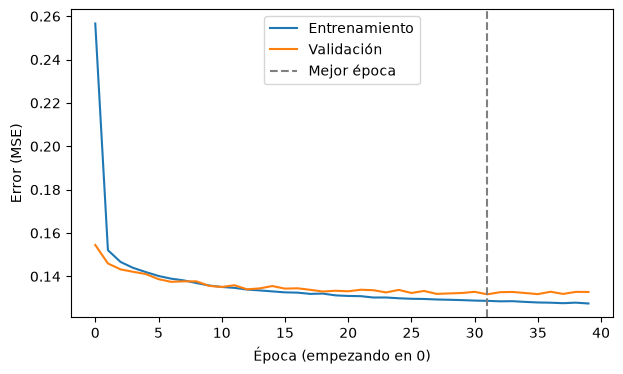

,modelo,MAE (€),RMSE (€),R² (euros),R² (log)
0,Lineal · entrenamiento,85680.120,156167.146,0.797,0.811
1,Lineal · validación,84918.975,155495.823,0.801,0.815
2,MLP · entrenamiento,69597.103,124739.938,0.871,0.873
3,MLP · validación,71022.859,126184.112,0.869,0.869


In [58]:
from pathlib import Path

def predecir_log_precio(red, X_tensor, media_y, desv_y):
    '''Devuelve el log-precio predicho, ya en su escala original (no estandarizada)'''
    red.eval()
    with torch.no_grad():
        salida = red(X_tensor)          # tensor (N, 1) en escala estandarizada
    salida = salida.numpy()             # lo pasamos a array de NumPy
    salida = salida.reshape(-1)         # (N, 1) -> (N,)
    log_precio = salida * desv_y + media_y   # deshacemos la estandarización
    return log_precio

# Gráfica de la curva de aprendizaje
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(historial_train, label="Entrenamiento")
ax.plot(historial_val, label="Validación")
ax.axvline(mejor_epoca - 1, color="gray", linestyle="--", label="Mejor época")   # la lista empieza en 0
ax.set_xlabel("Época (empezando en 0)")
ax.set_ylabel("Error (MSE)")
ax.legend()
carpeta_figuras = Path("../figuras")
carpeta_figuras.mkdir(exist_ok=True)
fig.savefig(carpeta_figuras / "curva_aprendizaje_mlp.png", dpi=200)
plt.show()

# Resultados del MLP, añadidos a los de la regresión lineal
pred_train = predecir_log_precio(red, X_train_t, media_y, desv_y)
pred_val = predecir_log_precio(red, X_val_t, media_y, desv_y)
resultados.append(evaluar("MLP · entrenamiento", y_train, pred_train))
resultados.append(evaluar("MLP · validación", y_val, pred_val))
pd.DataFrame(resultados).round(3)

## 5. Resultados y próximos pasos

**Resultados en validación** (el conjunto de prueba no se ha usado todavía; se reserva para la evaluación final). *La tabla siguiente recoge las cifras de la versión entregada el 13/11; la ejecución actual puede variar ligeramente, ver la tabla de la sección 4.*

| Modelo | MAE (€) | RMSE (€) | R² (euros) |
|---|---|---|---|
| Regresión lineal | 84.919 | 155.496 | 0,801 |
| Perceptrón multicapa | 71.022 | 126.184 | 0,869 |

El MLP mejora a la regresión lineal en las tres métricas, y no hay sobreajuste: los errores de entrenamiento y validación son muy parecidos.

**Limitaciones:** los datos son de 2018, por lo que el modelo no sirve para tasar a precios actuales; son precios de anuncio, no de venta.

**Pendiente para la Entrega 3**
- Añadir latitud y longitud como variables.
- Afinar el MLP (arquitectura, regularización y funciones de activación).
- Algoritmo genético para optimizar los hiperparámetros.
- Versión de clasificación en categorías de precio (regresión logística y MLP).
- Evaluación final sobre el conjunto de prueba.
- Contraste de los precios de 2018 con el índice de precios de vivienda del INE.